# 03 - Modelo preditivo

Tech Challenge Fase 1 - Case NPS Preditivo

Esta é a parte 4 do desafio. A ideia é usar o que a EDA mostrou para prever, antes da pesquisa, quais pedidos têm mais chance de virar detrator, e assim a empresa poder agir antes da nota ruim.

## Estratégia

O enunciado sugere duas abordagens: regressão (estimar a nota de 0 a 10) e classificação (separar satisfeitos e insatisfeitos). Testei as duas, mas o modelo principal é de classificação, por motivos de negócio:

- A decisão da operação é binária: agir ou não agir sobre aquele pedido. Uma nota prevista de 6,3 ou 5,8 não muda nada na prática; "risco alto de detrator" muda.
- O modelo de classificação entrega uma probabilidade, e com ela dá para escolher um ponto de corte de acordo com a capacidade da equipe que vai fazer o contato.
- A regressão entra como comparação, usando as métricas vistas na aula de regressão (MAE, RMSE e R²).

Alvo, seguindo a definição da etapa de target: a probabilidade de que um pedido gere uma nota de detrator (abaixo de 7,0) na pesquisa aplicada após o fim da jornada. No código é a coluna `flag_detrator` (1 = detrator).

Momento da previsão: depois da entrega e do fechamento do atendimento, antes da pesquisa. Por isso só entram variáveis que já existem nesse momento.

Caminho que segui, de acordo com o material de CRISP-DM:

1. Separar treino e teste (o teste só é usado no final).
2. Criar uma linha de base, para ter com o que comparar.
3. Começar por modelos simples e interpretáveis (regressão logística e árvore de decisão) e só depois testar um mais complexo (random forest).
4. Comparar os modelos com validação cruzada no treino.
5. Avaliar o escolhido no teste com métricas de classificação (precision, recall, F1, AUC) e escolher o ponto de corte pensando no negócio.
6. Explicar como o modelo seria usado na prática.

In [19]:
import json
import sys
import warnings
from pathlib import Path

import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.ticker as mtick
import seaborn as sns

from sklearn.model_selection import train_test_split, StratifiedKFold, cross_validate, GridSearchCV
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.dummy import DummyClassifier
from sklearn.linear_model import LogisticRegression, LinearRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (classification_report, confusion_matrix, roc_auc_score, roc_curve,
                             precision_score, recall_score, f1_score,
                             mean_absolute_error, mean_squared_error, r2_score)

PASTA_PROJETO = Path.cwd().parent
sys.path.append(str(PASTA_PROJETO / "src"))

warnings.filterwarnings("ignore", category=FutureWarning)
pd.set_option("display.float_format", lambda x: f"{x:,.3f}")

PASTA_FIGURAS = PASTA_PROJETO / "reports" / "figures"
PASTA_MODELOS = PASTA_PROJETO / "models"
SEMENTE = 42  # para os resultados serem sempre os mesmos

In [20]:
# mesmo padrão visual da EDA
COR_PRINCIPAL = "#2a78d6"
COR_DESTAQUE = "#eb6834"
COR_CINZA = "#b5b3ad"

plt.rcParams.update({
    "figure.dpi": 110,
    "figure.facecolor": "white",
    "axes.spines.top": False,
    "axes.spines.right": False,
    "axes.grid": True,
    "axes.axisbelow": True,
    "grid.color": "#e6e5e0",
    "grid.linewidth": 0.7,
    "axes.titlesize": 11,
    "axes.titleweight": "bold",
    "axes.titlelocation": "left",
    "font.size": 10,
})


def salvar_figura(fig, nome_arquivo):
    fig.savefig(PASTA_FIGURAS / nome_arquivo, bbox_inches="tight", dpi=150)

## 1. Seleção das variáveis

A seleção segue a linha do tempo do pedido e as decisões do notebook 01 e da EDA:

- Entram: atraso, contatos com o SAC, tempo de resolução e as demais variáveis de pedido, entrega e cliente. A EDA mostrou que só as três primeiras pesam de verdade, mas deixei as outras entrarem para o próprio modelo confirmar isso. A região entra como categoria.
- Não entram, por vazamento de dados: `repeat_purchase_30d` (acontece depois da pesquisa e é igual a nota >= 8) e `csat_internal_score` (outra nota de satisfação, coletada junto ou depois do NPS).
- Fica fora do modelo principal: `complaints_count`, porque não sei se a contagem é só desse pedido nem se inclui reclamações feitas depois da pesquisa. Testo ela em um cenário separado na seção 5.
- Fora também: ids, a própria nota e as colunas criadas só para os gráficos da EDA (faixas e flags).

In [21]:
df = pd.read_csv(PASTA_PROJETO / "data" / "processed" / "nps_tratado.csv")

VARIAVEIS_NUMERICAS = [
    "delivery_delay_days", "customer_service_contacts", "resolution_time_days",
    "delivery_time_days", "delivery_attempts", "freight_value", "order_value",
    "discount_value", "items_quantity", "payment_installments",
    "customer_age", "customer_tenure_months",
]
VARIAVEIS_CATEGORICAS = ["customer_region"]
VARIAVEIS_MODELO = VARIAVEIS_NUMERICAS + VARIAVEIS_CATEGORICAS
ALVO = "flag_detrator"

X = df[VARIAVEIS_MODELO]
y = df[ALVO]
print("Pedidos:", len(df), "| variáveis de entrada:", len(VARIAVEIS_MODELO))
print(y.value_counts(normalize=True).rename({1: "detrator", 0: "não detrator"}).round(3))

Pedidos: 2500 | variáveis de entrada: 13
flag_detrator
detrator       0.844
não detrator   0.156
Name: proportion, dtype: float64


Um ponto importante: aqui a classe detrator é a maioria (84%). A acurácia sozinha engana, porque um modelo que chama todo mundo de detrator já acerta 84%.

## 2. Separação entre treino e teste

Separei 80% para treino e 20% para teste, de forma estratificada (mantendo a mesma proporção de detratores nas duas partes).

Todas as escolhas (modelo e parâmetros) são feitas só com o treino, usando validação cruzada de 5 partes. O teste fica guardado para a avaliação final, para não contaminar o resultado.

In [22]:
X_treino, X_teste, y_treino, y_teste = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=SEMENTE
)
print(f"Treino: {len(X_treino)} pedidos | {y_treino.mean():.1%} detratores")
print(f"Teste:  {len(X_teste)} pedidos | {y_teste.mean():.1%} detratores")

validacao_cruzada = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEMENTE)

Treino: 2000 pedidos | 84.4% detratores
Teste:  500 pedidos | 84.4% detratores


Preparação das variáveis dentro de um Pipeline: as numéricas são padronizadas (média 0 e desvio 1, o que a regressão logística precisa para comparar os coeficientes) e a região vira colunas 0/1. Colocar isso dentro do Pipeline garante que a padronização é calculada só com os dados de treino de cada etapa.

In [23]:
preparacao = ColumnTransformer([
    ("numericas", StandardScaler(), VARIAVEIS_NUMERICAS),
    ("categoricas", OneHotEncoder(drop="first"), VARIAVEIS_CATEGORICAS),
])


def montar_pipeline(modelo):
    return Pipeline([("preparacao", preparacao), ("modelo", modelo)])

## 3. Comparação dos modelos

Comecei com uma linha de base (chuta sempre a classe mais comum) e depois, na ordem sugerida no material, regressão logística, árvore de decisão e random forest. Para os três modelos testei alguns valores de parâmetros com `GridSearchCV`, escolhendo pelo AUC (Area Under the Curve) na validação cruzada, já que o AUC mede se o modelo consegue ordenar bem os pedidos do maior para o menor risco, independente do ponto de corte.

In [24]:
candidatos = {
    "Regressão logística": (LogisticRegression(max_iter=1000), {"modelo__C": [0.01, 0.1, 1, 10]}),
    "Árvore de decisão": (DecisionTreeClassifier(random_state=SEMENTE),
                          {"modelo__max_depth": [2, 3, 4, 5, 6, 8], "modelo__min_samples_leaf": [10, 30, 60]}),
    "Random forest": (RandomForestClassifier(n_estimators=300, random_state=SEMENTE),
                      {"modelo__max_depth": [3, 5, 8], "modelo__min_samples_leaf": [10, 30]}),
}

modelos_ajustados = {}
for nome, (modelo, parametros) in candidatos.items():
    busca = GridSearchCV(montar_pipeline(modelo), parametros, cv=validacao_cruzada, scoring="roc_auc")
    busca.fit(X_treino, y_treino)
    modelos_ajustados[nome] = busca.best_estimator_
    print(f"{nome:20s} melhores parâmetros: {busca.best_params_}")

Regressão logística  melhores parâmetros: {'modelo__C': 0.1}
Árvore de decisão    melhores parâmetros: {'modelo__max_depth': 5, 'modelo__min_samples_leaf': 60}
Random forest        melhores parâmetros: {'modelo__max_depth': 8, 'modelo__min_samples_leaf': 30}


In [25]:
metricas = {
    "AUC": "roc_auc",
    "Recall": "recall",
    "Precision": "precision",
    "F1": "f1",
    "Acurácia": "accuracy",
}

linhas = []
todos = {"Linha de base (todos detratores)": montar_pipeline(DummyClassifier(strategy="most_frequent")),
         **modelos_ajustados}
for nome, pipeline in todos.items():
    resultado = cross_validate(pipeline, X_treino, y_treino, cv=validacao_cruzada, scoring=metricas)
    linha = {"modelo": nome}
    for nome_metrica in metricas:
        linha[nome_metrica] = resultado[f"test_{nome_metrica}"].mean()
    linhas.append(linha)

comparacao = pd.DataFrame(linhas).set_index("modelo")
comparacao

,AUC,Recall,Precision,F1,Acurácia
modelo,,,,,
Linha de base (todos detratores),0.500,1.000,0.844,0.915,0.844
Regressão logística,0.874,0.970,0.883,0.924,0.866
Árvore de decisão,0.833,0.950,0.883,0.915,0.851
Random forest,0.854,1.000,0.844,0.915,0.844


O que dá para tirar dessa tabela:

- A linha de base mostra a armadilha da acurácia: 84% de acerto e recall de 100% sem aprender nada. O AUC de 0,5 entrega que ela não separa nada.
- A regressão logística teve o melhor AUC (cerca de 0,87), acima da árvore e da random forest. Faz sentido com a EDA: a nota cai de forma quase linear com os dias de atraso e com os contatos, que é exatamente o tipo de relação que a regressão logística captura bem.
- As métricas de recall, precision e F1 desta tabela usam o corte padrão de 50%, que não é necessariamente o melhor para o negócio. A random forest, por exemplo, nesse corte acaba chamando todo mundo de detrator e fica igual à linha de base. Isso é tratado na seção 4.3.

Escolha: regressão logística. Além de ser a melhor no AUC, é a mais simples, o que o material destaca como critério importante. Não faria sentido usar um modelo mais complexo que performa pior.

## 4. Avaliação do modelo escolhido no teste

In [26]:
modelo_final = modelos_ajustados["Regressão logística"]
prob_teste = modelo_final.predict_proba(X_teste)[:, 1]

auc_teste = roc_auc_score(y_teste, prob_teste)
print(f"AUC no teste: {auc_teste:.3f}")
print(f"AUC na validação cruzada: {comparacao.loc['Regressão logística', 'AUC']:.3f}")

AUC no teste: 0.839
AUC na validação cruzada: 0.874


O AUC no teste (0,84) ficou um pouco abaixo da validação cruzada (0,87), mas na mesma faixa. Não há sinal de que o modelo decorou o treino. Na prática, um AUC de 0,84 quer dizer que, pegando um detrator e um não detrator ao acaso, em 84% das vezes o modelo dá um risco maior para o detrator.

### 4.1 Curva ROC

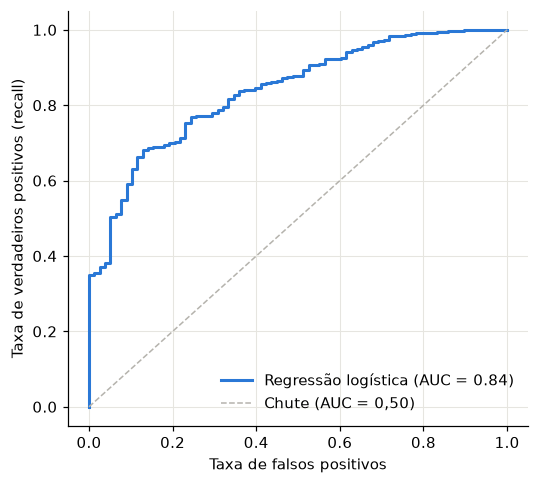

In [27]:
fpr, tpr, _ = roc_curve(y_teste, prob_teste)

fig, ax = plt.subplots(figsize=(5, 4.5))
ax.plot(fpr, tpr, color=COR_PRINCIPAL, linewidth=2, label=f"Regressão logística (AUC = {auc_teste:.2f})")
ax.plot([0, 1], [0, 1], color=COR_CINZA, linestyle="--", linewidth=1, label="Chute (AUC = 0,50)")
ax.set_xlabel("Taxa de falsos positivos")
ax.set_ylabel("Taxa de verdadeiros positivos (recall)")
ax.legend(loc="lower right", frameon=False)
plt.tight_layout()
salvar_figura(fig, "10_curva_roc.png")
plt.show()

O modelo separa bem detratores dos demais

### 4.2 O que o modelo aprendeu

Como as variáveis foram padronizadas, dá para comparar o tamanho dos coeficientes. Coeficiente positivo aumenta o risco de detrator.

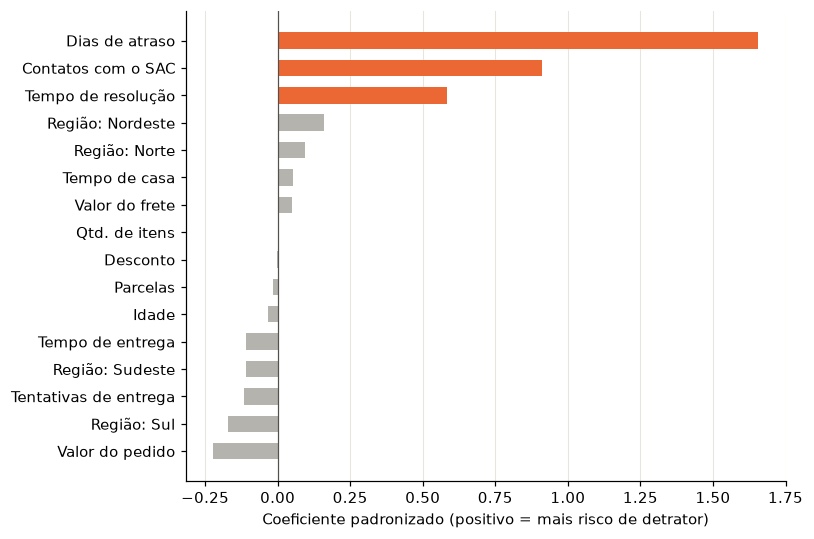

delivery_delay_days          1.656
customer_service_contacts    0.910
resolution_time_days         0.583
order_value                 -0.223
customer_region_Sul         -0.171
customer_region_Nordeste     0.158
delivery_attempts           -0.115
customer_region_Sudeste     -0.111
delivery_time_days          -0.111
customer_region_Norte        0.096
customer_tenure_months       0.052
freight_value                0.049
customer_age                -0.034
payment_installments        -0.016
items_quantity               0.002
discount_value              -0.001
dtype: float64

In [28]:
nomes_colunas = modelo_final.named_steps["preparacao"].get_feature_names_out()
coeficientes = pd.Series(modelo_final.named_steps["modelo"].coef_[0], index=nomes_colunas)
coeficientes.index = coeficientes.index.str.replace("numericas__", "").str.replace("categoricas__", "")
coeficientes = coeficientes.sort_values()

nomes_amigaveis = {
    "delivery_delay_days": "Dias de atraso",
    "customer_service_contacts": "Contatos com o SAC",
    "resolution_time_days": "Tempo de resolução",
    "delivery_time_days": "Tempo de entrega",
    "delivery_attempts": "Tentativas de entrega",
    "freight_value": "Valor do frete",
    "order_value": "Valor do pedido",
    "discount_value": "Desconto",
    "items_quantity": "Qtd. de itens",
    "payment_installments": "Parcelas",
    "customer_age": "Idade",
    "customer_tenure_months": "Tempo de casa",
}
rotulos = [nomes_amigaveis.get(c, c.replace("customer_region_", "Região: ")) for c in coeficientes.index]

fig, ax = plt.subplots(figsize=(7.5, 5))
cores = [COR_DESTAQUE if abs(v) >= 0.3 else COR_CINZA for v in coeficientes.values]
ax.barh(rotulos, coeficientes.values, color=cores, height=0.6)
ax.axvline(0, color="#52514e", linewidth=0.8)
ax.grid(True, axis="x")
ax.grid(False, axis="y")
ax.set_xlabel("Coeficiente padronizado (positivo = mais risco de detrator)")
plt.tight_layout()
salvar_figura(fig, "11_coeficientes_modelo.png")
plt.show()

coeficientes.sort_values(key=abs, ascending=False).round(3)

O modelo aprendeu o mesmo que a EDA: atraso e atendimento

O modelo confirma a EDA de forma independente: atraso é de longe a variável mais importante, seguida por contatos com o SAC e tempo de resolução. As demais têm peso bem menor, a maior delas é o valor do pedido (-0,22, pedidos mais caros com risco um pouco menor), um efeito pequeno que também tinha aparecido na regressão da EDA. Isso dá mais confiança no modelo, porque ele não está se apoiando em alguma variável sem sentido de negócio.

### 4.3 Escolha do ponto de corte

O modelo entrega uma probabilidade, e a decisão de agir ou não depende de um ponto de corte. Ele não deve ser escolhido no automático (50%), e sim pelo custo de cada erro:

- Falso positivo: a empresa age sobre um pedido que não ia virar detrator. Custo: o tempo do contato e, se houver, a compensação oferecida.
- Falso negativo: o modelo deixa passar um futuro detrator. Custo: o cliente que provavelmente não volta a comprar e fala mal da marca.

A tabela abaixo mostra o que acontece no teste com diferentes cortes:

In [29]:
linhas_corte = []
for corte in [0.5, 0.6, 0.7, 0.8, 0.85, 0.9, 0.95]:
    previsto = (prob_teste >= corte).astype(int)
    linhas_corte.append({
        "corte": corte,
        "pct_pedidos_sinalizados": previsto.mean() * 100,
        "precision": precision_score(y_teste, previsto),
        "recall": recall_score(y_teste, previsto),
        "f1": f1_score(y_teste, previsto),
    })
tabela_cortes = pd.DataFrame(linhas_corte).set_index("corte")
tabela_cortes.round(3)

,pct_pedidos_sinalizados,precision,recall,f1
corte,,,,
0.500,93.800,0.881,0.979,0.927
0.600,89.800,0.889,0.945,0.916
0.700,83.800,0.902,0.896,0.899
0.800,75.800,0.926,0.832,0.876
0.850,67.600,0.944,0.756,0.839
0.900,56.600,0.968,0.649,0.777
0.950,40.600,0.980,0.472,0.637


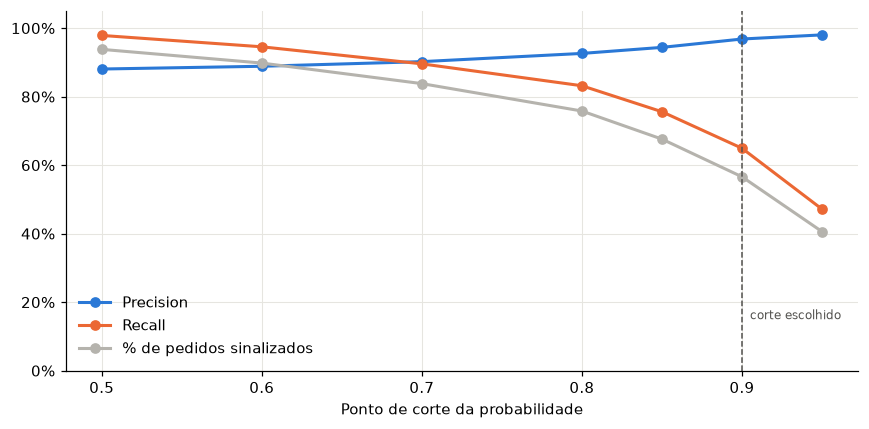

In [30]:
fig, ax = plt.subplots(figsize=(8, 4))
ax.plot(tabela_cortes.index, tabela_cortes["precision"] * 100, marker="o", color=COR_PRINCIPAL, linewidth=2, label="Precision")
ax.plot(tabela_cortes.index, tabela_cortes["recall"] * 100, marker="o", color=COR_DESTAQUE, linewidth=2, label="Recall")
ax.plot(tabela_cortes.index, tabela_cortes["pct_pedidos_sinalizados"], marker="o", color=COR_CINZA, linewidth=2,
        label="% de pedidos sinalizados")
ax.axvline(0.9, color="#52514e", linestyle="--", linewidth=1)
ax.text(0.905, 15, "corte escolhido", fontsize=8, color="#52514e")
ax.set_ylim(0, 105)
ax.yaxis.set_major_formatter(mtick.PercentFormatter())
ax.set_xlabel("Ponto de corte da probabilidade")
ax.legend(frameon=False, loc="lower left")
plt.tight_layout()
salvar_figura(fig, "12_ponto_de_corte.png")
plt.show()

Subir o corte deixa a lista mais certeira, mas menor

Com o corte padrão de 50% o modelo sinaliza mais de 90% dos pedidos. Como 84% da base é detratora, isso é quase o mesmo que não ter modelo: a equipe não teria como agir sobre todos.

Escolhi o corte de 90%, pensando em uma equipe com capacidade limitada que precisa saber por onde começar:

- O modelo sinaliza um pouco mais da metade dos pedidos.
- Desses, 97% realmente viram detratores (precision), então quase nenhum contato é desperdiçado.
- Ele encontra cerca de 65% de todos os detratores (recall).

Se a empresa tiver mais capacidade, o corte pode descer (por exemplo, 80% pega 83% dos detratores com precision de 93%). Essa escolha é do negócio, e o modelo permite ajustar sem retreinar.

              precision    recall  f1-score   support

Não detrator      0.318     0.885     0.468        78
    Detrator      0.968     0.649     0.777       422

    accuracy                          0.686       500
   macro avg      0.643     0.767     0.623       500
weighted avg      0.867     0.686     0.729       500



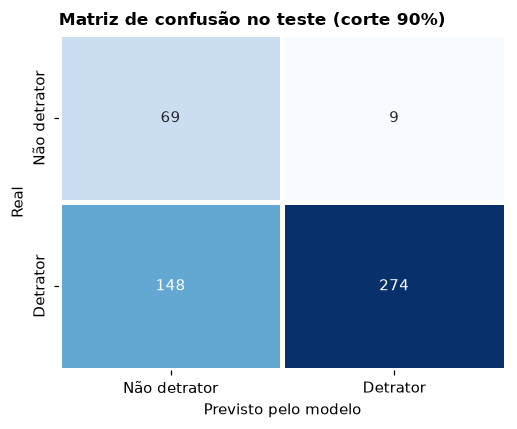

In [31]:
CORTE_ESCOLHIDO = 0.9
previsto_teste = (prob_teste >= CORTE_ESCOLHIDO).astype(int)

print(classification_report(y_teste, previsto_teste, target_names=["Não detrator", "Detrator"], digits=3))

matriz = confusion_matrix(y_teste, previsto_teste)
fig, ax = plt.subplots(figsize=(4.8, 4))
sns.heatmap(matriz, annot=True, fmt="d", cmap="Blues", cbar=False, linewidths=2, linecolor="white",
            xticklabels=["Não detrator", "Detrator"], yticklabels=["Não detrator", "Detrator"], ax=ax)
ax.set_xlabel("Previsto pelo modelo")
ax.set_ylabel("Real")
ax.set_title(f"Matriz de confusão no teste (corte {CORTE_ESCOLHIDO:.0%})")
plt.tight_layout()
salvar_figura(fig, "13_matriz_confusao.png")
plt.show()

### 4.4 Faixas de risco

Para a operação, em vez de um sim ou não, acho mais útil entregar faixas de risco, parecido com o exemplo de fraude do material (score alto bloqueia, médio pede verificação, baixo aprova). Conferindo no teste quantos pedidos de cada faixa realmente viraram detratores:

In [32]:
def classificar_risco(probabilidade):
    return pd.cut(probabilidade, bins=[0, 0.7, 0.9, 1.0], labels=["Baixo", "Médio", "Alto"], include_lowest=True)


faixas_teste = pd.DataFrame({"faixa_risco": classificar_risco(prob_teste), "detrator": y_teste.values})
resumo_faixas = faixas_teste.groupby("faixa_risco", observed=True).agg(
    pedidos=("detrator", "size"),
    pct_detratores_reais=("detrator", "mean"),
)
resumo_faixas["pct_da_base"] = resumo_faixas["pedidos"] / resumo_faixas["pedidos"].sum() * 100
resumo_faixas["pct_detratores_reais"] *= 100
resumo_faixas.round(1)

,pedidos,pct_detratores_reais,pct_da_base
faixa_risco,,,
Baixo,81,54.300,16.200
Médio,136,76.500,27.200
Alto,283,96.800,56.600


As faixas separam bem: na faixa alta praticamente todo mundo vira detrator, e na faixa baixa a proporção é bem menor que a média da base (84%). Mesmo na faixa baixa ainda tem muito detrator, o que mostra que existe uma parte da insatisfação que as variáveis operacionais da base não explicam (qualidade do produto, expectativa do cliente etc.).

## 5. Cenário com reclamações

Como combinado na EDA, testei separadamente o que acontece se `complaints_count` entrar no modelo:

In [33]:
variaveis_com_reclamacoes = VARIAVEIS_NUMERICAS + ["complaints_count"]
preparacao_reclamacoes = ColumnTransformer([
    ("numericas", StandardScaler(), variaveis_com_reclamacoes),
    ("categoricas", OneHotEncoder(drop="first"), VARIAVEIS_CATEGORICAS),
])
pipeline_reclamacoes = Pipeline([
    ("preparacao", preparacao_reclamacoes),
    ("modelo", LogisticRegression(max_iter=1000, C=modelo_final.named_steps["modelo"].C)),
])
colunas = variaveis_com_reclamacoes + VARIAVEIS_CATEGORICAS
auc_reclamacoes = cross_validate(pipeline_reclamacoes, df.loc[X_treino.index, colunas], y_treino,
                                 cv=validacao_cruzada, scoring="roc_auc")["test_score"].mean()
print(f"AUC (validação cruzada) sem reclamações: {comparacao.loc['Regressão logística', 'AUC']:.3f}")
print(f"AUC (validação cruzada) com reclamações: {auc_reclamacoes:.3f}")

AUC (validação cruzada) sem reclamações: 0.874
AUC (validação cruzada) com reclamações: 0.896


O AUC sobe um pouco com as reclamações. Mesmo assim mantenho o modelo sem elas. Se essa contagem incluir reclamações feitas depois da pesquisa, esse ganho é vazamento e não vai se repetir na prática. Antes de usar, precisaria confirmar como e quando a coluna é preenchida. Se ela for só de reclamações deste pedido e anteriores à pesquisa, vale incluir em uma próxima versão.

## 6. Comparação: modelo de regressão

Para cumprir a outra abordagem sugerida no desafio, treinei uma regressão linear múltipla para prever a nota de 0 a 10, com as mesmas variáveis e a mesma separação de treino e teste, avaliando com as métricas da aula de regressão.

In [34]:
nota_treino = df.loc[X_treino.index, "nps_score"]
nota_teste = df.loc[X_teste.index, "nps_score"]

modelo_regressao = montar_pipeline(LinearRegression()).fit(X_treino, nota_treino)
nota_prevista = modelo_regressao.predict(X_teste)

mae = mean_absolute_error(nota_teste, nota_prevista)
rmse = np.sqrt(mean_squared_error(nota_teste, nota_prevista))
r2 = r2_score(nota_teste, nota_prevista)
print(f"MAE:  {mae:.2f} pontos")
print(f"RMSE: {rmse:.2f} pontos")
print(f"R²:   {r2:.3f}")

MAE:  1.38 pontos
RMSE: 1.76 pontos
R²:   0.489


Em média a regressão erra a nota em 1,4 ponto, o erro absoluto médio (MAE), e explica cerca de metade da variação da nota (R²), o mesmo que já tinha aparecido na regressão da EDA. Para uma escala de 0 a 10 em que a diferença entre detrator e neutro é de 1 ponto, esse erro é grande demais para usar a nota prevista diretamente na classificação de cada cliente.

Por isso a regressão serve bem para explicar (quantos pontos cada dia de atraso tira, como na EDA), e a classificação serve melhor para agir.

## 7. Salvando o modelo

In [35]:
caminho_modelo = PASTA_MODELOS / "modelo_detrator_logistica.joblib"
joblib.dump(modelo_final, caminho_modelo)

ficha = {
    "modelo": "Regressão logística (scikit-learn)",
    "alvo": "flag_detrator (1 = nota de NPS abaixo de 7,0)",
    "variaveis": VARIAVEIS_MODELO,
    "parametro_C": modelo_final.named_steps["modelo"].C,
    "corte_recomendado": CORTE_ESCOLHIDO,
    "faixas_de_risco": {"Baixo": "< 0,70", "Médio": "0,70 a 0,90", "Alto": ">= 0,90"},
    "auc_validacao_cruzada": round(float(comparacao.loc["Regressão logística", "AUC"]), 3),
    "auc_teste": round(float(auc_teste), 3),
    "precision_teste_no_corte": round(float(precision_score(y_teste, previsto_teste)), 3),
    "recall_teste_no_corte": round(float(recall_score(y_teste, previsto_teste)), 3),
}
with open(PASTA_MODELOS / "ficha_modelo.json", "w", encoding="utf-8") as arquivo:
    json.dump(ficha, arquivo, ensure_ascii=False, indent=2)

print("Modelo salvo em:", caminho_modelo.relative_to(PASTA_PROJETO))

Modelo salvo em: models/modelo_detrator_logistica.joblib


Exemplo de uso do modelo salvo, como seria feito no dia a dia para um pedido novo:

In [36]:
modelo_carregado = joblib.load(caminho_modelo)

pedidos_exemplo = pd.DataFrame([
    # no prazo e sem contato com o SAC
    {"delivery_delay_days": 0, "customer_service_contacts": 0, "resolution_time_days": 0,
     "delivery_time_days": 7, "delivery_attempts": 1, "freight_value": 35.0, "order_value": 300.0,
     "discount_value": 20.0, "items_quantity": 2, "payment_installments": 3, "customer_age": 40,
     "customer_tenure_months": 24, "customer_region": "Sudeste"},
    # 3 dias de atraso e 2 contatos com o SAC
    {"delivery_delay_days": 3, "customer_service_contacts": 2, "resolution_time_days": 6,
     "delivery_time_days": 7, "delivery_attempts": 1, "freight_value": 35.0, "order_value": 300.0,
     "discount_value": 20.0, "items_quantity": 2, "payment_installments": 3, "customer_age": 40,
     "customer_tenure_months": 24, "customer_region": "Sudeste"},
])
probabilidades = modelo_carregado.predict_proba(pedidos_exemplo)[:, 1]
pedidos_exemplo["prob_detrator"] = probabilidades.round(3)
pedidos_exemplo["faixa_risco"] = classificar_risco(probabilidades)
pedidos_exemplo[["delivery_delay_days", "customer_service_contacts", "prob_detrator", "faixa_risco"]]

,delivery_delay_days,customer_service_contacts,prob_detrator,faixa_risco
0,0,0,0.150,Baixo
1,3,2,0.984,Alto


## 8. Como a empresa usaria isso na prática

Fluxo proposto:

1. Todo dia, rodar o modelo para os pedidos que foram entregues ou tiveram o atendimento encerrado e que ainda não receberam a pesquisa.
2. Separar os pedidos por faixa de risco e mandar para quem vai agir:
   - Risco alto: contato proativo do atendimento (pedido de desculpas, explicação do atraso, resolução de pendências). É a fila prioritária.
   - Risco médio: ação mais leve e automática, como uma mensagem explicando o que aconteceu.
   - Risco baixo: segue o fluxo normal.
3. Em paralelo, usar os achados da EDA na causa: avisar o atraso antes de o cliente procurar o SAC, priorizar na fila do SAC quem tem pedido atrasado e rever os prazos prometidos.


## 9. Ficha do modelo

Seguindo a ideia de documentar o modelo para ele não virar uma caixa-preta:

| Item | Descrição |
|---|---|
| Objetivo | Estimar a probabilidade de um pedido gerar um detrator (nota abaixo de 7,0) antes da pesquisa de NPS |
| Modelo | Regressão logística com variáveis padronizadas (scikit-learn), escolhida por ter o melhor AUC e ser interpretável |
| Variáveis | Atraso, contatos com o SAC, tempo de resolução, tempo de entrega, tentativas, frete, valor, desconto, itens, parcelas, idade, tempo de casa e região |
| Fora do modelo | repeat_purchase_30d e csat_internal_score (vazamento); complaints_count (origem incerta) |
| Dados | 2.500 pedidos, 80% treino e 20% teste estratificado; validação cruzada de 5 partes |
| Desempenho | AUC 0,87 na validação cruzada e 0,84 no teste; no corte de 0,9, precision de 97% e recall de 65% |
| Uso | Priorizar contato proativo com pedidos de risco alto, depois da entrega e antes da pesquisa |
| Limitações | Base com sinais de ser simulada; sem data, então não foi possível testar o modelo no tempo; explica só parte da insatisfação |
| Manutenção | Acompanhar mensalmente a taxa de detratores por faixa de risco; retreinar se a taxa mudar muito ou se mudar a regra da pesquisa, a transportadora ou o prazo prometido |

## Resumo

- Modelo escolhido: regressão logística, com AUC de 0,84 no teste.
- O modelo usa as mesmas variáveis que a EDA apontou: atraso em primeiro lugar, depois contatos com o SAC e tempo de resolução.
- Com corte de 0,9, 97% dos pedidos sinalizados viram detratores, e o modelo encontra cerca de 2 em cada 3 detratores.
- A regressão para prever a nota erra em média 1,4 ponto, então serve mais para explicar do que para decidir.
- Próximo passo para o negócio: validar a ação proativa com um teste A/B.